# 03 — Entraînements supervisés et validation imbriquée par groupes

**Quatre régressions indépendantes** : limite d'élasticité, résistance maximale à
la traction, allongement et énergie Charpy. Pour chaque cible, comparer une
constante médiane, Ridge, SVR RBF, Random Forest et kNN. Les modèles ont été
confirmés comme faisant partie du cours par l'utilisateur. COREG est différé.

Ce notebook contient directement les pipelines et les entraînements. Il ne
dépend ni d'un package `src/`, ni de l'exécution/import d'un autre notebook.
Le master conserve ses NaN ; seuls les trains étiquetés servent aux fits appris.

**Portée Charpy** : prédire `charpy_J` avec la température `charpy_temp_C` en
entrée. La documentation originale définit des couples température (°C)/énergie
(J), mais ne précise pas le protocole de chaque ligne. Nous entraînons donc une
**expérience exploratoire sur les couples rapportés**, sans déclarer les 861
énergies homogènes ni toutes directement mesurées. Les signatures de séries sont
des diagnostics, pas une classification validée. Aucune ligne n'est reclassée à
partir de sa seule énergie 28/100 J. Ces résultats restent séparés des conclusions
sur la traction ; la validation par source demeure nécessaire avant utilisation.

Sources : [documentation originale](../data/raw/welddb.info),
[spécification active](../specs/spec.md). Un exemple primaire de modélisation
E(T), avec température en entrée et énergie moyenne de plusieurs essais en
sortie, est décrit par [Bhadeshia, MacKay et Svensson, 1995, pp. 3–5](https://www.phase-trans.msm.cam.ac.uk/abstracts/toughness.pdf).
Cet article ne valide pas les protocoles de toutes les lignes de notre master.


In [1]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import platform
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import joblib
from IPython.display import display
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.exceptions import ConvergenceWarning
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import IterativeImputer, SimpleImputer
from sklearn.linear_model import BayesianRidge, Ridge
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.compose import TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, ParameterGrid
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from joblib import Memory, parallel_config
from threadpoolctl import threadpool_limits

SEED = 42
N_JOBS = 3  # recherches parallèles ; chaque forêt utilise un seul worker
PRIMARY_SET = 'A1_13'
PRIMARY_IMPUTER = 'iterative'
TARGETS = ['yield_strength', 'uts', 'elongation', 'charpy_J']
CAT = 'weld_process'
PROCESS_COL = CAT
CORE13 = ['C', 'Si', 'Mn', 'S', 'P', 'current_A', 'voltage_V',
          'heat_input_kJmm', 'interpass_C', 'pwht_temp_C', 'pwht_time_h',
          'O_ppm', 'N_ppm']
NONNEG = CORE13  # la température d'essai Charpy peut être négative
TARGET_UNITS = {'yield_strength': 'MPa', 'uts': 'MPa',
                'elongation': 'points de %', 'charpy_J': 'J'}
TARGET_NAMES = {'yield_strength': "Limite d'élasticité", 'uts': 'Résistance maximale',
                'elongation': 'Allongement', 'charpy_J': 'Énergie Charpy — exploratoire'}
MODEL_NAMES = {'median_y': 'Médiane de y', 'ridge': 'Ridge', 'svr_rbf': 'SVR RBF',
               'random_forest': 'Random Forest', 'knn': 'kNN'}
PARAM_GRIDS = {
    'median_y': {},
    'ridge': {'model__alpha': [0.01, 0.1, 1, 10, 100, 1000]},
    'svr_rbf': {'model__regressor__C': [1, 10, 100],
                'model__regressor__gamma': ['scale', 0.05],
                'model__regressor__epsilon': [0.05, 0.2]},
    'random_forest': {'model__min_samples_leaf': [1, 2, 5],
                     'model__max_depth': [None, 10],
                     'model__max_features': [0.5, 1.0]},
    'knn': {'model__n_neighbors': [3, 5, 9, 15], 'model__p': [1, 2]},
}

def numeric_features(target):
    if target not in TARGETS:
        raise ValueError(f'Cible non prévue : {target}')
    return list(CORE13) + (['charpy_temp_C'] if target == 'charpy_J' else [])

def task_features(target):
    return numeric_features(target) + [CAT]

def eligible_rows(frame, target):
    # La température d'essai est une condition connue pour E(T), jamais imputée
    # pour fabriquer un couple Charpy dont la condition d'essai serait inconnue.
    mask = frame['in_strict13'] & frame[target].notna()
    if target == 'charpy_J':
        mask &= frame.charpy_temp_C.notna()
    return frame.loc[mask].copy()

def outer_partitions(frame, target, outer_fold):
    eligible = eligible_rows(frame, target)
    train = eligible.loc[eligible.outer_fold != outer_fold].reset_index(drop=True)
    valid = eligible.loc[eligible.outer_fold == outer_fold].reset_index(drop=True)
    if train.empty or valid.empty:
        raise ValueError(f'Partition vide : {target}, pli {outer_fold}')
    if not set(train.group).isdisjoint(valid.group):
        raise AssertionError('Un groupe externe est partagé entre train et validation.')
    return train, valid

def inner_splits(train, outer_fold):
    col = f'inner_fold_when_outer{outer_fold}'
    if not set(train[col].unique()).issubset({0, 1, 2}):
        raise AssertionError('Les lignes externes ne doivent pas entrer dans les plis internes.')
    splits = []
    for inner_fold in range(3):
        tr = np.flatnonzero(train[col].to_numpy() != inner_fold)
        va = np.flatnonzero(train[col].to_numpy() == inner_fold)
        if len(tr) < 15 or len(va) < 2:
            raise ValueError('Effectif interne insuffisant pour les grilles prévues.')
        if not set(train.iloc[tr].group).isdisjoint(train.iloc[va].group):
            raise AssertionError('Un groupe interne est partagé.')
        splits.append((tr, va))
    return splits

def regression_metrics(y, prediction):
    y, prediction = np.asarray(y, float), np.asarray(prediction, float)
    if not np.isfinite(y).all() or not np.isfinite(prediction).all():
        raise ValueError('Labels/prédictions non finis.')
    return {'MAE': float(mean_absolute_error(y, prediction)),
            'RMSE': float(mean_squared_error(y, prediction) ** 0.5),
            'R2': float(r2_score(y, prediction))}


## 1. Identité des données et rappel de préparation

Lecture vérifiée de `master.csv` et des plis exportés par le notebook 02.
Brut : 1 652 lignes × 44 champs. Quatre alias restent marqués dans le master,
mais sont exclus des expériences ; 1 648 lignes sont dédupliquées. La cohorte
`in_strict13` contient 1 555 lignes/44 groupes, avec au plus deux absences parmi
les treize entrées numériques A1_13. Pour Charpy, la température d'essai doit
en plus être connue ; elle n'entre pas dans ce seuil historique.

`N` = non rapporté, donc NaN, jamais zéro ; `<L` → L/2 et intervalle → milieu,
avec provenance conservée. Les unités douteuses sont en quarantaine sans
conversion conjecturale ; les annotations N total/résiduel restent séparées.
Les valeurs observées, zéros et extrêmes sont préservés. Seuls ShMA→MMA et
SMA→SA sont regroupés. Aucun label absent n'est imputé.


In [2]:
PROJECT_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                     if (p / 'sujet.md').is_file() and (p / 'notebooks').is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Ouvrir le notebook depuis le dépôt ou notebooks/.')
DATA = PROJECT_ROOT / 'data/processed/modeling'
OUT = PROJECT_ROOT / 'data/processed/experiments/salh_supervised_v1'
OUT.mkdir(parents=True, exist_ok=True)
manifest = json.loads((DATA / 'manifest.json').read_text())
for filename, digest in manifest['files'].items():
    assert hashlib.sha256((DATA / filename).read_bytes()).hexdigest() == digest, filename
assert hashlib.sha256((PROJECT_ROOT / 'data/raw/welddb.data').read_bytes()).hexdigest() == manifest['raw_sha256']
assert manifest['feature_sets'][PRIMARY_SET] == CORE13
assert manifest['seed'] == SEED
master = pd.read_csv(DATA / 'master.csv')
folds = pd.read_csv(DATA / 'folds.csv')
data = master.loc[master.in_strict13].merge(
    folds, on=['raw_row_id', 'group'], validate='one_to_one')
assert len(data) == 1555 and data.group.nunique() == 44
assert not data.is_duplicate_excess.any()
assert data.raw_row_id.is_unique
assert data.groupby('group').outer_fold.nunique().max() == 1
protocol_candidates = pd.read_csv(DATA / 'charpy_protocol_candidates.csv')
assert protocol_candidates.group.is_unique
FEATURE_UNITS = {c: manifest['units'][c] for c in CORE13 + ['charpy_temp_C']}

display(pd.Series({'lignes_master': len(master), 'après_déduplication': len(folds),
                   'lignes_cohorte': len(data), 'groupes_cohorte': data.group.nunique(),
                   'lignes_cohorte_avec_absence_X': int(data[CORE13].isna().any(axis=1).sum()),
                   'cellules_X_absentes': int(data[CORE13].isna().sum().sum())}).to_frame('effectif'))
target_stats = []
for target in TARGETS:
    dt = eligible_rows(data, target)
    y = dt[target]
    target_stats.append({'cible': target, 'unité': TARGET_UNITS[target],
                         'labels_cohorte': int(data[target].notna().sum()),
                         'éligibles_tâche': len(dt), 'groupes': dt.group.nunique(),
                         'min': y.min(), 'médiane': y.median(), 'moyenne': y.mean(),
                         'écart_type': y.std(), 'max': y.max(),
                         'statut': 'exploratoire' if target == 'charpy_J' else 'traction'})
target_stats = pd.DataFrame(target_stats)
display(target_stats.round(3))
display(pd.DataFrame({'unité': FEATURE_UNITS,
                      'absences_cohorte': data[list(FEATURE_UNITS)].isna().sum(),
                      'moyenne_observée': data[list(FEATURE_UNITS)].mean(),
                      'écart_type_observé': data[list(FEATURE_UNITS)].std()}).round(3))
print('Procédés présents dans la cohorte :')
display(data[CAT].value_counts().rename('lignes').to_frame())


,effectif
lignes_master,1652
après_déduplication,1648
lignes_cohorte,1555
groupes_cohorte,44
lignes_cohorte_avec_absence_X,607
cellules_X_absentes,1075


,cible,unité,labels_cohorte,éligibles_tâche,groupes,min,médiane,moyenne,écart_type,max,statut
0,yield_strength,MPa,706,706,40,315.0,496.0,507.875,92.050,920.0,traction
1,uts,MPa,677,677,39,447.0,576.0,595.978,89.535,1151.0,traction
2,elongation,points de %,631,631,34,10.6,26.6,26.148,4.884,36.4,traction
3,charpy_J,J,861,861,24,3.0,100.0,87.351,50.530,270.0,exploratoire


,unité,absences_cohorte,moyenne_observée,écart_type_observé
C,wt%,0,0.075,0.023
Si,wt%,0,0.329,0.113
Mn,wt%,0,1.205,0.381
S,wt%,0,0.009,0.011
P,wt%,0,0.013,0.020
current_A,A,178,277.554,187.405
voltage_V,V,178,27.428,12.503
heat_input_kJmm,kJ/mm,0,1.655,1.273
interpass_C,degC,0,203.211,38.577
pwht_temp_C,degC,0,305.994,286.100


Procédés présents dans la cohorte :


,lignes
weld_process,
MMA,1121
SA,227
FCA,87
TSA,83
NGSAW,18
NGGMA,7
SAA,4
GTAA,4
GMAA,4


## 2. Entrées et justification des quatre tâches indépendantes

| Famille | Entrées numériques | Unités |
| --- | --- | --- |
| Composition de base | C, Si, Mn, S, P | % massique |
| Traces | O_ppm, N_ppm | ppm massiques |
| Électricité | current_A, voltage_V | A, V |
| Soudage thermique | heat_input_kJmm, interpass_C | kJ/mm, °C |
| Traitement après soudage | pwht_temp_C, pwht_time_h | °C, h |
| Condition d'essai, uniquement Charpy | charpy_temp_C | °C |

Ajouter `weld_process` comme catégorie. Ni/Cr/Mo restent hors de la référence
à cause de leur couverture plus faible ; A0_11/A1b_16 sont des sensibilités
différées, pas des schémas sélectionnés à partir des scores externes. Aucune
ACP ni sélection automatique des variables n'est appliquée dans ces pipelines.

Les autres propriétés mécaniques, dureté, FATT50, microstructure, identifiants,
groupes, flags et numéros de plis ne sont jamais des predictors. Le procédé
est une entrée ; le groupe sert uniquement à la validation.

Les trois propriétés de traction sont corrélées mais ont un sens physique
distinct. Des modèles séparés utilisent tous les labels propres à chaque cible
(706/677/631/861), tandis que seules 141 lignes renseignent les quatre sorties.
La température Charpy ne devient pas une entrée des régressions de traction.


In [3]:
FEATURES_BY_TARGET = {target: task_features(target) for target in TARGETS}
for target, features in FEATURES_BY_TARGET.items():
    forbidden = TARGETS + ['reduction_area', 'hardness_value', 'fatt50', 'raw_row_id',
                           'group', 'outer_fold', 'is_duplicate_excess', 'in_strict13']
    assert not set(forbidden).intersection(features)
    assert ('charpy_temp_C' in features) == (target == 'charpy_J')
display(pd.DataFrame([{'cible': target, 'entrées_numériques': numeric_features(target),
                      'entrée_catégorielle': CAT, 'nombre_numériques': len(numeric_features(target))}
                     for target in TARGETS]))
print('Trois sorties traction simultanément connues :', len(data[TARGETS[:3]].dropna()))
print('Quatre sorties simultanément connues :', len(data[TARGETS].dropna()))
display(data.groupby('group').agg(lignes=('raw_row_id', 'size'),
        élasticité=('has_yield_strength', 'sum'), UTS=('has_uts', 'sum'),
        allongement=('has_elongation', 'sum'), Charpy=('has_charpy_J', 'sum')))
display(protocol_candidates.loc[protocol_candidates.group.isin(
    eligible_rows(data, 'charpy_J').group), ['group', 'n', 'signature', 'candidate_task', 'status']])


,cible,entrées_numériques,entrée_catégorielle,nombre_numériques
0,yield_strength,"[C, Si, Mn, S, P, current_A, voltage_V, heat_i...",weld_process,13
1,uts,"[C, Si, Mn, S, P, current_A, voltage_V, heat_i...",weld_process,13
2,elongation,"[C, Si, Mn, S, P, current_A, voltage_V, heat_i...",weld_process,13
3,charpy_J,"[C, Si, Mn, S, P, current_A, voltage_V, heat_i...",weld_process,14


Trois sorties traction simultanément connues : 609
Quatre sorties simultanément connues : 141


,lignes,élasticité,UTS,allongement,Charpy
group,,,,,
Alekseev&-CMnNi-1991,7,7,7,7,0
Birmingham,9,8,0,0,0
Blond&-1984,18,9,9,9,6
Chandel&-1985,23,4,4,4,19
Ditt,19,5,5,0,14
EPRI-TR-101394,12,12,12,12,0
Es-Souni&-Cu/CMn-1990,12,12,12,12,0
Evans-Al/CMn-1990,59,18,18,18,35
Evans-AlEl9Cr1Mo-1994,13,13,13,13,0


,group,n,signature,candidate_task,status
0,EvansLetter,104.0,fixed_energy_varying_T,T(E_fixed) — ex. T100J/T28J,hypothesis — verify against the source publica...
1,Evans-StressRelief-1991,94.0,varying_E,E(T),hypothesis — verify against the source publica...
2,SvenGret-1990,80.0,varying_E,E(T),hypothesis — verify against the source publica...
3,Evans-Nb/Mn-1991,78.0,fixed_energy_varying_T,T(E_fixed) — ex. T100J/T28J,hypothesis — verify against the source publica...
4,Mart,63.0,varying_E,E(T),hypothesis — verify against the source publica...
5,Pat-1981,63.0,varying_E,E(T),hypothesis — verify against the source publica...
6,Evans-AlTi-1994,60.0,fixed_energy_varying_T,T(E_fixed) — ex. T100J/T28J,hypothesis — verify against the source publica...
7,Evans-Ti/Mn-1992,40.0,fixed_energy_varying_T,T(E_fixed) — ex. T100J/T28J,hypothesis — verify against the source publica...
8,Evans-Al/CMn-1990,35.0,fixed_energy_varying_T,T(E_fixed) — ex. T100J/T28J,hypothesis — verify against the source publica...
9,Evans-Cr/CMn-1989,31.0,fixed_energy_varying_T,T(E_fixed) — ex. T100J/T28J,hypothesis — verify against the source publica...


## 3. GroupKFold imbriqué : cinq plis externes, trois internes

Les groupes sont des séries conservatrices inférées des identifiants et reliées
par les doublons. Des observations apparentées restent ensemble. Ils ne sont
pas des publications confirmées ; les variantes de noms ne sont pas fusionnées
(`MERGE_NAME_VARIANTS=False`). Les splits exportés portent sur les 1 648 lignes
dédupliquées, puis sont restreints à la cohorte et aux labels de chaque cible.
Ils restent les mêmes pour toutes les familles de modèles.

Pour chacun des cinq plis externes :
1. Réserver entièrement ses groupes comme validation externe.
2. Sur le train externe étiqueté, utiliser les trois sous-plis par groupes déjà
   exportés. Chaque essai ajuste sa pipeline sur le train interne uniquement.
3. Choisir les paramètres par **MAE moyenne non pondérée des trois validations
   internes**. La validation externe ne participe à aucun choix.
4. Réajuster la pipeline choisie sur tout le train externe étiqueté ; prédire
   le pli externe une seule fois et enregistrer MAE, RMSE et R².

GroupKFold est sans mélange ; la graine 42 concerne les estimateurs, pas un
tirage aléatoire des plis. Le pool non étiqueté n'est pas utilisé dans ces
expériences supervisées. Aucune pseudo-étiquette n'est générée.


In [4]:
fold_summary = data.groupby('outer_fold').agg(
    lignes=('raw_row_id', 'size'), groupes=('group', 'nunique'),
    élasticité=('has_yield_strength', 'sum'), UTS=('has_uts', 'sum'),
    allongement=('has_elongation', 'sum'), Charpy=('has_charpy_J', 'sum'))
display(fold_summary)
partition_rows = []
inner_rows = []
for target in TARGETS:
    for outer_fold in range(5):
        train, valid = outer_partitions(data, target, outer_fold)
        partition_rows.append({'target': target, 'outer_fold': outer_fold,
                               'n_train': len(train), 'n_valid': len(valid),
                               'groups_train': train.group.nunique(), 'groups_valid': valid.group.nunique()})
        for inner_fold, (tr, va) in enumerate(inner_splits(train, outer_fold)):
            inner_rows.append({'target': target, 'outer_fold': outer_fold,
                               'inner_fold': inner_fold, 'n_train': len(tr), 'n_valid': len(va),
                               'groups_train': train.iloc[tr].group.nunique(),
                               'groups_valid': train.iloc[va].group.nunique()})
partition_counts = pd.DataFrame(partition_rows)
inner_counts = pd.DataFrame(inner_rows)
display(partition_counts)
display(inner_counts)
partition_counts.to_csv(OUT / 'partition_counts.csv', index=False)
inner_counts.to_csv(OUT / 'inner_partition_counts.csv', index=False)
target_stats.to_csv(OUT / 'target_statistics.csv', index=False)


,lignes,groupes,élasticité,UTS,allongement,Charpy
outer_fold,,,,,,
0,330,8,132,138,139,186
1,330,9,166,142,141,152
2,298,9,145,162,137,157
3,287,8,120,121,103,175
4,310,10,143,114,111,191


,target,outer_fold,n_train,n_valid,groups_train,groups_valid
0,yield_strength,0,574,132,34,6
1,yield_strength,1,540,166,32,8
2,yield_strength,2,561,145,32,8
3,yield_strength,3,586,120,32,8
4,yield_strength,4,563,143,30,10
5,uts,0,539,138,32,7
6,uts,1,535,142,33,6
7,uts,2,515,162,30,9
8,uts,3,556,121,31,8
9,uts,4,563,114,30,9


,target,outer_fold,inner_fold,n_train,n_valid,groups_train,groups_valid
0,yield_strength,0,0,333,241,22,12
1,yield_strength,0,1,427,147,23,11
2,yield_strength,0,2,388,186,23,11
3,yield_strength,1,0,379,161,22,10
4,yield_strength,1,1,324,216,20,12
5,yield_strength,1,2,377,163,22,10
6,yield_strength,2,0,365,196,21,11
7,yield_strength,2,1,393,168,22,10
8,yield_strength,2,2,364,197,21,11
9,yield_strength,3,0,391,195,21,11


## 4. Preprocessing local au train et détail de chaque pipeline

Les quatre pipelines prédictives commencent par le même `FoldPreprocessor` :

**X du train → standardisation numérique + one-hot du procédé → imputation
itérative → projection PWHT → estimateur.**

- Moyenne/écart-type calculés seulement sur les entrées observées du train.
  Une colonne constante utilise un dénominateur 1.
- Catégories du procédé apprises sur le train ; catégorie inconnue en validation
  → toutes ses indicatrices valent zéro.
- IterativeImputer/BayesianRidge, initialisation médiane, ordre ascendant,
  `max_iter=100`, `tol=1e-3`, `skip_complete=False`, graine 42. Bornes non négatives
  pour les imputations concernées ; température d'essai Charpy autorisée négative.
  Les valeurs déjà observées ne sont pas changées dans leur unité originale.
- Pour un PWHT absent, projection sur un couple température/durée réellement
  présent dans le train, en distance standardisée. Une composante observée
  impose un couple compatible. Aucun couple compatible, une colonne entièrement
  absente ou une non-convergence → erreur explicite, sans fallback silencieux.

| Modèle | Étapes après preprocessing | Réglage interne |
| --- | --- | --- |
| Médiane de y | Aucun preprocessing X ; constante médiane des seuls y du train | Aucun |
| Ridge | Régression linéaire avec pénalité L2 ; y reste en unité originale | 6 alpha |
| SVR RBF | StandardScaler sur y du train → SVR → inversion de l'échelle de y | 12 C/gamma/epsilon |
| Random Forest | 300 arbres ; y reste en unité originale | 12 leaf/depth/max_features |
| kNN | Moyenne uniforme des voisins dans X standardisé/encodé ; y en unité originale | 8 k/distance |

La standardisation de X est nécessaire à l'imputation et aux méthodes sensibles
aux distances ; elle est aussi conservée pour la forêt afin de partager le même
preprocessing. La baseline n'a besoin d'aucune entrée renseignée.

Le cache de pipeline évite de refaire un preprocessing identique pour plusieurs
paramètres d'estimateur : la clé contient le train X/y et les paramètres du
transformer. Il ne partage aucun fit entre trains différents. L'imputation
médiane reste le contrôle historique du notebook 02, pas une option sélectionnée
sur les scores externes de cette comparaison. Aucun fit global d'ACP ou d'imputation.


In [5]:
class FoldPreprocessor(BaseEstimator, TransformerMixin):
    """À ajuster sur les lignes d'entraînement d'un pli uniquement.

    1. standardisation des entrées numériques (moyenne/écart-type du train, NaN ignorés) ;
    2. one-hot du procédé (catégories du train ; inconnue -> vecteur nul) ;
    3. imputation : 'iterative' (IterativeImputer/BayesianRidge, init médiane, ordre ascendant,
       max_iter=100, tol=1e-3, random_state=42, bornes physiques >= 0) ou 'median' ;
    4. PWHT : un couple (température, durée) imputé est projeté sur le couple réel du train
       le plus proche (distance en écarts-types du train), en respectant une valeur observée.
    Une colonne entièrement absente du train est refusée plutôt que fabriquée.
    Sortie : entrées standardisées + indicatrices du procédé. Les cibles n'entrent jamais ici.
    """

    def __init__(self, num_cols, cat_col=PROCESS_COL, method='iterative', max_iter=100,
                 tol=1e-3, random_state=SEED):
        self.num_cols, self.cat_col, self.method = num_cols, cat_col, method
        self.max_iter, self.tol, self.random_state = max_iter, tol, random_state

    def _encode(self, X):
        Z = (X[self.num_cols].to_numpy(float) - self.mu_) / self.sd_
        C = np.stack([(X[self.cat_col] == c).to_numpy(float) for c in self.cats_], axis=1) \
            if self.cat_col else np.empty((len(X), 0))
        return np.hstack([Z, C])

    def fit(self, X, y=None):
        Xn = X[self.num_cols].astype(float)
        empty = Xn.columns[Xn.notna().sum() == 0].tolist()
        if empty:
            raise ValueError(f'Colonnes entièrement absentes du train : {empty}')
        self.mu_ = Xn.mean().to_numpy()
        self.sd_ = Xn.std(ddof=0).replace(0, 1).to_numpy()
        self.cats_ = sorted(X[self.cat_col].dropna().unique()) if self.cat_col else []
        Z = self._encode(X)
        lo = np.full(Z.shape[1], -np.inf)
        for i, c in enumerate(self.num_cols):
            if c in NONNEG:
                lo[i] = (0 - self.mu_[i]) / self.sd_[i]
        if self.method == 'iterative':
            self.imp_ = IterativeImputer(estimator=BayesianRidge(), initial_strategy='median',
                                         imputation_order='ascending', max_iter=self.max_iter,
                                         tol=self.tol, random_state=self.random_state,
                                         skip_complete=False, min_value=lo, keep_empty_features=True)
        elif self.method == 'median':
            self.imp_ = SimpleImputer(strategy='median', keep_empty_features=True)
        else:
            raise ValueError(self.method)
        with warnings.catch_warnings():
            warnings.simplefilter('ignore', ConvergenceWarning)
            self.imp_.fit(Z)
        self.converged_ = (self.method != 'iterative') or (self.imp_.n_iter_ < self.max_iter)
        self.n_iter_ = getattr(self.imp_, 'n_iter_', 0)
        if not self.converged_:
            raise RuntimeError('Imputation itérative non convergée : réviser le schéma dans le train.')
        # couples PWHT réels du train
        self.pw_idx_ = [self.num_cols.index(c) for c in ('pwht_temp_C', 'pwht_time_h')
                        if c in self.num_cols]
        if len(self.pw_idx_) == 2:
            P = Z[:, self.pw_idx_]
            self.pw_pairs_ = np.unique(P[~np.isnan(P).any(axis=1)], axis=0)
            if len(self.pw_pairs_) == 0:
                raise ValueError('Aucun couple PWHT complet dans le train.')
        return self

    def transform(self, X):
        Z = self._encode(X)
        miss = np.isnan(Z)
        out = self.imp_.transform(Z)
        if len(self.pw_idx_) == 2 and len(self.pw_pairs_):
            i, j = self.pw_idx_
            for r in np.where(miss[:, i] | miss[:, j])[0]:
                cand = self.pw_pairs_
                if not miss[r, i]:   # température observée : couples compatibles seulement
                    cand = cand[np.isclose(cand[:, 0], Z[r, i])]
                if not miss[r, j]:
                    cand = cand[np.isclose(cand[:, 1], Z[r, j])]
                if len(cand) == 0:
                    raise ValueError(f'Aucun couple PWHT compatible pour la ligne {X.index[r]}.')
                best = cand[np.argmin(((cand - out[r, [i, j]]) ** 2).sum(axis=1))]
                out[r, i] = Z[r, i] if not miss[r, i] else best[0]
                out[r, j] = Z[r, j] if not miss[r, j] else best[1]
        return out

    def get_feature_names_out(self, input_features=None):
        return np.array([str(c) for c in self.num_cols] + [f'{self.cat_col}={c}' for c in self.cats_], dtype=object)


In [6]:
def make_pipeline(model_name, target, memory=None):
    if model_name == 'median_y':
        # DummyRegressor ignore les valeurs de X ; seule la médiane de y est apprise.
        return Pipeline([('model', DummyRegressor(strategy='median'))])
    estimators = {
        'ridge': Ridge(),
        'svr_rbf': TransformedTargetRegressor(
            regressor=SVR(kernel='rbf'), transformer=StandardScaler()),
        'random_forest': RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=1),
        'knn': KNeighborsRegressor(weights='uniform'),
    }
    if model_name not in estimators:
        raise ValueError(model_name)
    return Pipeline([
        ('preprocess', FoldPreprocessor(numeric_features(target), cat_col=CAT,
                                       method=PRIMARY_IMPUTER, random_state=SEED)),
        ('model', estimators[model_name]),
    ], memory=memory)

def tune_pipeline(train, target, model_name, outer_fold, memory=None, n_jobs=N_JOBS):
    pipeline = make_pipeline(model_name, target, memory=memory)
    search = GridSearchCV(pipeline, PARAM_GRIDS[model_name],
                          scoring='neg_mean_absolute_error',
                          cv=inner_splits(train, outer_fold),
                          refit=True, n_jobs=n_jobs, error_score='raise',
                          return_train_score=False)
    # Le refit final est sur le seul train externe, jamais sur sa validation.
    with parallel_config(backend='threading'):
        with threadpool_limits(limits=1):
            search.fit(train[task_features(target)], train[target])
    return search

for model_name, grid in PARAM_GRIDS.items():
    assert set(grid).issubset(make_pipeline(model_name, TARGETS[0]).get_params())
display(pd.DataFrame([{'modèle': MODEL_NAMES[name], 'configurations': len(ParameterGrid(grid)),
                      'y_standardisé': name == 'svr_rbf'} for name, grid in PARAM_GRIDS.items()]))


,modèle,configurations,y_standardisé
0,Médiane de y,1,False
1,Ridge,6,False
2,SVR RBF,12,True
3,Random Forest,12,False
4,kNN,8,False


## 5. Vérification des transformations avant les recherches

Contrôler les 60 trains internes et les 20 trains externes : convergence,
absence de colonne vide, sorties finies et préservation des valeurs observées.
Ces contrôles ne consultent pas les scores pour changer de méthode.
La validation est uniquement transformée avec le fit du train.


In [7]:
def check_transformed_observations(pre, frame):
    transformed = pre.transform(frame)
    assert np.isfinite(transformed).all()
    raw_numeric = frame[pre.num_cols].to_numpy(float)
    restored = transformed[:, :len(pre.num_cols)] * pre.sd_ + pre.mu_
    observed = np.isfinite(raw_numeric)
    assert np.allclose(restored[observed], raw_numeric[observed])

preflight_rows = []
with threadpool_limits(limits=1):
    for target in TARGETS:
        for outer_fold in range(5):
            train, valid = outer_partitions(data, target, outer_fold)
            split_frames = [('external_train', -1, train, valid)]
            split_frames += [('internal_train', j, train.iloc[tr], train.iloc[va])
                             for j, (tr, va) in enumerate(inner_splits(train, outer_fold))]
            for scope, j, tr, va in split_frames:
                pre = FoldPreprocessor(numeric_features(target), method=PRIMARY_IMPUTER).fit(tr)
                check_transformed_observations(pre, tr)
                check_transformed_observations(pre, va)
                preflight_rows.append({'target': target, 'outer_fold': outer_fold,
                                       'scope': scope, 'inner_fold': j, 'n_train': len(tr),
                                       'converged': pre.converged_, 'iterations': pre.n_iter_})
        print(f'Preprocessing vérifié : {target}', flush=True)
preflight = pd.DataFrame(preflight_rows)
assert len(preflight) == 80 and preflight.converged.all()
display(preflight.groupby(['target', 'scope']).iterations.agg(['count', 'min', 'max']))
preflight.to_csv(OUT / 'preprocessing_checks.csv', index=False)


Preprocessing vérifié : yield_strength


Preprocessing vérifié : uts


Preprocessing vérifié : elongation


Preprocessing vérifié : charpy_J


count  min  max
target         scope                          
charpy_J       external_train      5    4    8
               internal_train     15    3   20
elongation     external_train      5    4    7
               internal_train     15    4   14
uts            external_train      5    4    6
               internal_train     15    3   13
yield_strength external_train      5    4    7
               internal_train     15    3    9

## 6. Entraînements réglés et prédictions externes

Les budgets sont fixés avant l'évaluation : 39 configurations (baseline comprise)
par cible/pli externe, trois validations internes par configuration, puis un refit
par modèle. Soit 2 440 fits d'estimateurs pour les quatre cibles et cinq plis
externes. Le preprocessing est remis à zéro dans chaque train ; le cache ne
change pas ce protocole. Les sorties CSV sont checkpointées après chaque modèle.

MAE = moyenne des erreurs absolues ; RMSE = racine de la moyenne des erreurs
au carré ; R² compare l'erreur quadratique à une prédiction égale à la moyenne
observée de la validation et peut être négatif. Les unités sont MPa, points de
pourcentage ou J. Les moyennes par pli sont non pondérées ; les scores OOF
regroupent les prédictions externes et pondèrent implicitement par les lignes.


In [8]:
cache = Memory(OUT / 'pipeline_cache', verbose=0)
score_rows, prediction_frames, search_rows = [], [], []
outer_models = {}  # modèles entraînés accessibles dans ce noyau, sans refit global
started = time.perf_counter()
started_at = datetime.now(timezone.utc).isoformat()
for target in TARGETS:
    for outer_fold in range(5):
        train, valid = outer_partitions(data, target, outer_fold)
        for model_name in MODEL_NAMES:
            tick = time.perf_counter()
            search = tune_pipeline(train, target, model_name, outer_fold, memory=cache)
            prediction = search.predict(valid[task_features(target)])
            train_prediction = search.predict(train[task_features(target)])
            metrics = regression_metrics(valid[target], prediction)
            train_metrics = regression_metrics(train[target], train_prediction)
            pipeline = search.best_estimator_
            pre = pipeline.named_steps.get('preprocess')
            params = json.dumps(search.best_params_, ensure_ascii=False, sort_keys=True)
            score_rows.append({'target': target, 'model': model_name, 'outer_fold': outer_fold,
                               'unit': TARGET_UNITS[target], 'n_train': len(train), 'n_valid': len(valid),
                               'groups_train': train.group.nunique(), 'groups_valid': valid.group.nunique(),
                               'inner_MAE': -float(search.best_score_), 'best_params': params,
                               'imputer': PRIMARY_IMPUTER if pre is not None else 'none',
                               'preprocessing_iterations': pre.n_iter_ if pre is not None else 0,
                               'converged': bool(pre.converged_) if pre is not None else True,
                               'feature_set': PRIMARY_SET, 'seed': SEED,
                               'scope': 'exploratory_reported_pairs' if target == 'charpy_J' else 'traction',
                               'elapsed_seconds': time.perf_counter() - tick,
                               **metrics, **{f'train_{k}': v for k, v in train_metrics.items()}})
            pred = valid[['raw_row_id', 'weld_id', 'group', 'outer_fold']].copy()
            pred['target'], pred['model'] = target, model_name
            pred['unit'], pred['y_true'], pred['y_pred'] = TARGET_UNITS[target], valid[target].to_numpy(), prediction
            pred['charpy_temp_C'] = valid.charpy_temp_C.to_numpy() if target == 'charpy_J' else np.nan
            prediction_frames.append(pred)
            for candidate, config in enumerate(search.cv_results_['params']):
                row = {'target': target, 'model': model_name, 'outer_fold': outer_fold,
                       'candidate': candidate, 'params': json.dumps(config, sort_keys=True),
                       'mean_inner_MAE': -float(search.cv_results_['mean_test_score'][candidate]),
                       'std_inner_MAE': float(search.cv_results_['std_test_score'][candidate]),
                       'rank': int(search.cv_results_['rank_test_score'][candidate]),
                       'selected': candidate == search.best_index_}
                row.update({f'inner{j}_MAE': -float(search.cv_results_[f'split{j}_test_score'][candidate])
                            for j in range(3)})
                search_rows.append(row)
            # Le cache local n'est pas requis pour prédire avec le modèle déjà ajusté.
            pipeline.memory = None
            outer_models[(target, model_name, outer_fold)] = pipeline
            pd.DataFrame(score_rows).to_csv(OUT / 'outer_metrics.csv', index=False)
            pd.concat(prediction_frames, ignore_index=True).to_csv(OUT / 'outer_predictions.csv', index=False)
            pd.DataFrame(search_rows).to_csv(OUT / 'inner_search_results.csv', index=False)
            print(f'{target:15s} | pli {outer_fold} | {model_name:13s} | '
                  f'MAE={metrics["MAE"]:.3f} {TARGET_UNITS[target]} | '
                  f'R²={metrics["R2"]:.3f} | {time.perf_counter()-tick:.1f}s', flush=True)
scores = pd.DataFrame(score_rows)
predictions = pd.concat(prediction_frames, ignore_index=True)
search_results = pd.DataFrame(search_rows)
assert len(scores) == 100
assert len(search_results) == 780
assert scores.converged.all()
assert not predictions.duplicated(['target', 'model', 'raw_row_id']).any()
for target in TARGETS:
    expected = set(eligible_rows(data, target).raw_row_id)
    for model_name in MODEL_NAMES:
        actual = predictions.loc[(predictions.target == target) & (predictions.model == model_name)]
        assert set(actual.raw_row_id) == expected
        assert np.allclose(actual.y_true.to_numpy(),
                           actual.raw_row_id.map(master.set_index('raw_row_id')[target]).to_numpy())
total_seconds = time.perf_counter() - started
print(f'Expérience terminée : {len(scores)} évaluations externes, {total_seconds/60:.2f} minutes.')


yield_strength  | pli 0 | median_y      | MAE=56.667 MPa | R²=-0.027 | 0.0s


yield_strength  | pli 0 | ridge         | MAE=64.207 MPa | R²=-0.249 | 1.8s


yield_strength  | pli 0 | svr_rbf       | MAE=54.771 MPa | R²=0.107 | 1.2s


yield_strength  | pli 0 | random_forest | MAE=53.741 MPa | R²=0.154 | 12.4s


yield_strength  | pli 0 | knn           | MAE=60.888 MPa | R²=-0.040 | 0.8s


...

charpy_J        | pli 4 | ridge         | MAE=39.861 J | R²=0.206 | 3.0s


charpy_J        | pli 4 | svr_rbf       | MAE=40.950 J | R²=0.161 | 1.9s


charpy_J        | pli 4 | random_forest | MAE=37.014 J | R²=0.281 | 12.9s


charpy_J        | pli 4 | knn           | MAE=41.452 J | R²=0.038 | 1.2s


Expérience terminée : 100 évaluations externes, 5.98 minutes.


## 7. Comparaison des performances et lecture des limites

Moyenne et écart-type empirique des cinq plis externes ; l'écart-type n'est pas
un intervalle de confiance. Chaque famille a ses paramètres choisis dans les
plis internes. Le classement ci-dessous est descriptif : le score du meilleur
modèle du tableau n'est pas une estimation indépendante d'une sélection entre
familles. Pour évaluer une procédure de choix de famille, ce choix doit lui
aussi entrer dans la recherche interne. Aucun refit global ni modèle de production
n'est choisi en maximisant ce tableau.


Limite d'élasticité — MPa


,target,model,MAE_mean,MAE_std,RMSE_mean,RMSE_std,R2_mean,R2_std,train_MAE_mean,n_outer_folds,unit,n,OOF_MAE,OOF_RMSE,OOF_R2,MAE_gain_vs_median_y
17,yield_strength,random_forest,65.8763,10.6085,85.6483,15.0520,0.0786,0.1460,30.0775,5,MPa,706,66.5358,87.7215,0.0905,4.5724
19,yield_strength,svr_rbf,69.2827,12.8108,89.2624,15.9825,0.0042,0.1289,36.3783,5,MPa,706,70.1194,91.3579,0.0136,1.1660
18,yield_strength,ridge,69.9200,5.1745,90.8811,8.0869,-0.0536,0.1523,63.0221,5,MPa,706,69.9419,91.4806,0.0109,0.5286
16,yield_strength,median_y,70.4487,10.6818,92.5010,13.1041,-0.0731,0.0515,69.5957,5,MPa,706,70.7011,93.7798,-0.0394,0.0000
15,yield_strength,knn,76.8720,15.7497,98.6755,21.1471,-0.2076,0.1983,46.1723,5,MPa,706,77.4093,101.3205,-0.2133,-6.4234


Résistance maximale — MPa


,target,model,MAE_mean,MAE_std,RMSE_mean,RMSE_std,R2_mean,R2_std,train_MAE_mean,n_outer_folds,unit,n,OOF_MAE,OOF_RMSE,OOF_R2,MAE_gain_vs_median_y
12,uts,random_forest,57.6531,10.7801,76.2472,14.9492,0.1942,0.1539,23.7943,5,MPa,677,56.5240,75.9278,0.2798,15.0105
14,uts,svr_rbf,63.4032,12.7037,83.4292,16.7863,0.0388,0.1797,33.1295,5,MPa,677,62.0447,83.0177,0.1390,9.2604
13,uts,ridge,65.8818,15.1439,82.9911,20.5412,0.0544,0.2586,58.7199,5,MPa,677,64.7240,83.2815,0.1335,6.7819
10,uts,knn,66.6487,16.0023,88.6570,19.1856,-0.0885,0.2636,34.3096,5,MPa,677,65.0554,88.3187,0.0256,6.0149
11,uts,median_y,72.6636,15.2372,93.7286,22.7336,-0.1800,0.1138,68.7503,5,MPa,677,71.1448,93.6777,-0.0963,0.0000


Allongement — points de %


,target,model,MAE_mean,MAE_std,RMSE_mean,RMSE_std,R2_mean,R2_std,train_MAE_mean,n_outer_folds,unit,n,OOF_MAE,OOF_RMSE,OOF_R2,MAE_gain_vs_median_y
7,elongation,random_forest,3.5594,0.1826,4.4910,0.2245,0.1247,0.0823,1.3256,5,points de %,631,3.5511,4.4825,0.1563,0.5267
8,elongation,ridge,3.7326,0.3095,4.5730,0.4629,0.0942,0.1191,3.4331,5,points de %,631,3.7194,4.5663,0.1245,0.3535
9,elongation,svr_rbf,3.8801,0.3901,4.8240,0.5473,-0.0069,0.1418,2.3253,5,points de %,631,3.8501,4.8101,0.0285,0.2059
5,elongation,knn,3.9110,0.2523,5.0176,0.4489,-0.0925,0.1463,2.4676,5,points de %,631,3.8895,4.9988,-0.0492,0.1751
6,elongation,median_y,4.0860,0.3092,4.9622,0.4226,-0.0617,0.0466,4.0001,5,points de %,631,4.0905,4.9733,-0.0386,0.0000


Énergie Charpy — exploratoire — J


,target,model,MAE_mean,MAE_std,RMSE_mean,RMSE_std,R2_mean,R2_std,train_MAE_mean,n_outer_folds,unit,n,OOF_MAE,OOF_RMSE,OOF_R2,MAE_gain_vs_median_y
2,charpy_J,random_forest,34.7089,12.3557,46.5272,11.1448,0.0173,0.3060,8.3954,5,J,861,34.9569,47.4846,0.1159,1.3263
0,charpy_J,knn,34.9243,13.1172,49.3626,9.6445,-0.1387,0.4001,12.7347,5,J,861,35.5522,50.3542,0.0058,1.1109
3,charpy_J,ridge,35.7371,12.8699,45.8389,11.4796,0.0716,0.1320,34.1487,5,J,861,36.1631,47.2362,0.1251,0.2981
1,charpy_J,median_y,36.0352,16.9086,50.6026,11.6782,-0.1488,0.2514,36.7173,5,J,861,36.7584,52.0606,-0.0627,0.0000
4,charpy_J,svr_rbf,36.1422,8.5052,46.1161,8.6015,0.0352,0.1884,17.2801,5,J,861,36.4748,46.9699,0.1349,-0.1070


,target,outer_fold,model,n_train,n_valid,MAE,RMSE,R2,inner_MAE,preprocessing_iterations,best_params
0,yield_strength,0,median_y,574,132,56.6667,78.4642,-0.0272,73.1368,0,{}
1,yield_strength,0,ridge,574,132,64.2075,86.5358,-0.2494,70.3089,4,"{""model__alpha"": 100}"
2,yield_strength,0,svr_rbf,574,132,54.7709,73.1427,0.1074,76.2319,4,"{""model__regressor__C"": 1, ""model__regressor__..."
3,yield_strength,0,random_forest,574,132,53.7410,71.1920,0.1544,68.3700,4,"{""model__max_depth"": null, ""model__max_feature..."
4,yield_strength,0,knn,574,132,60.8884,78.9650,-0.0404,76.5847,4,"{""model__n_neighbors"": 15, ""model__p"": 2}"
...,...,...,...,...,...,...,...,...,...,...,...
95,charpy_J,4,median_y,670,191,44.1152,53.4688,-0.0058,34.5492,0,{}
96,charpy_J,4,ridge,670,191,39.8615,47.5158,0.2057,36.4231,4,"{""model__alpha"": 1000}"
97,charpy_J,4,svr_rbf,670,191,40.9497,48.8430,0.1607,35.8124,4,"{""model__regressor__C"": 1, ""model__regressor__..."
98,charpy_J,4,random_forest,670,191,37.0144,45.2214,0.2806,34.8195,4,"{""model__max_depth"": 10, ""model__max_features""..."


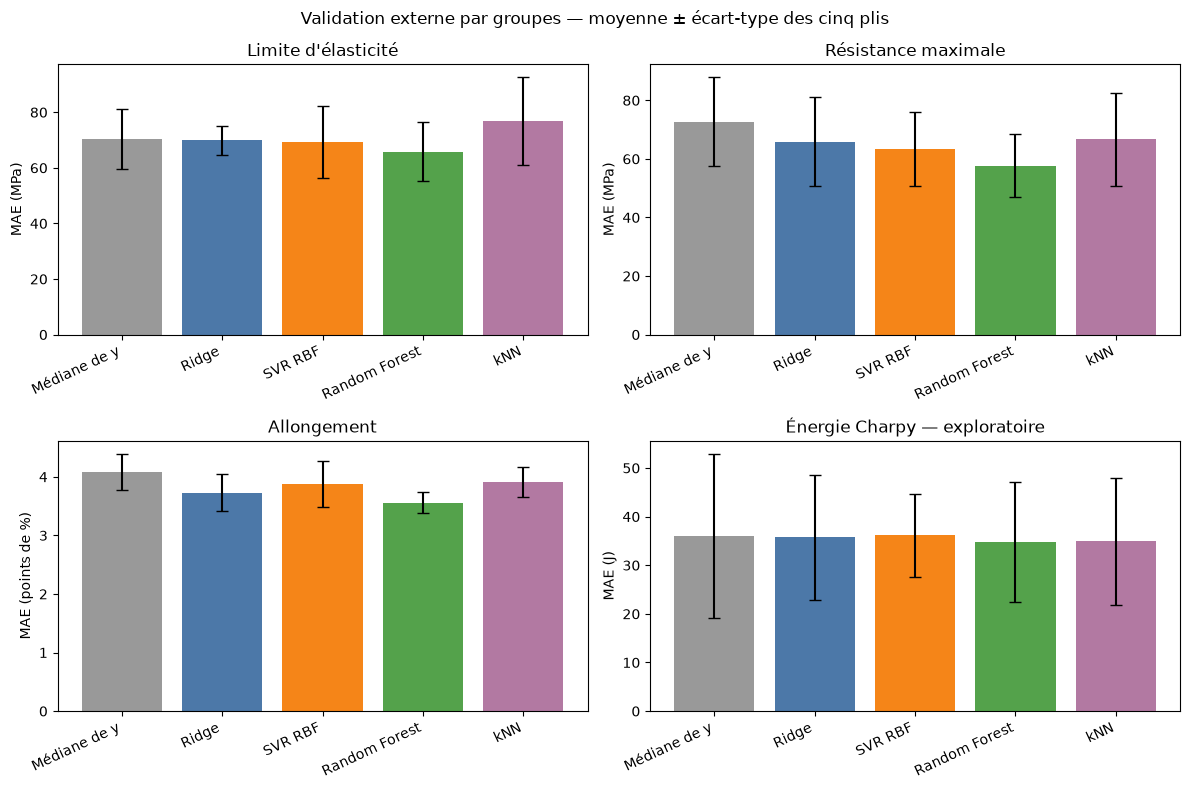

In [9]:
summary = scores.groupby(['target', 'model']).agg(
    MAE_mean=('MAE', 'mean'), MAE_std=('MAE', 'std'),
    RMSE_mean=('RMSE', 'mean'), RMSE_std=('RMSE', 'std'),
    R2_mean=('R2', 'mean'), R2_std=('R2', 'std'),
    train_MAE_mean=('train_MAE', 'mean'), n_outer_folds=('outer_fold', 'nunique')).reset_index()
summary['unit'] = summary.target.map(TARGET_UNITS)
oof_rows = []
for (target, model_name), group in predictions.groupby(['target', 'model']):
    oof_rows.append({'target': target, 'model': model_name, 'n': len(group),
                     **{f'OOF_{k}': v for k, v in regression_metrics(group.y_true, group.y_pred).items()}})
oof_metrics = pd.DataFrame(oof_rows)
summary = summary.merge(oof_metrics, on=['target', 'model'], validate='one_to_one')
baseline = summary.loc[summary.model == 'median_y'].set_index('target').MAE_mean
summary['MAE_gain_vs_median_y'] = summary.target.map(baseline) - summary.MAE_mean
summary.to_csv(OUT / 'metrics_summary.csv', index=False)
for target in TARGETS:
    print(TARGET_NAMES[target], '—', TARGET_UNITS[target])
    display(summary.loc[summary.target == target].sort_values('MAE_mean').round(4))
display(scores[['target', 'outer_fold', 'model', 'n_train', 'n_valid', 'MAE', 'RMSE', 'R2',
                'inner_MAE', 'preprocessing_iterations', 'best_params']].round(4))

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, target in zip(axes.flat, TARGETS):
    table = summary.loc[summary.target == target].set_index('model').loc[list(MODEL_NAMES)]
    ax.bar(range(len(table)), table.MAE_mean, yerr=table.MAE_std,
           capsize=4, color=['#999999', '#4C78A8', '#F58518', '#54A24B', '#B279A2'])
    ax.set_xticks(range(len(table)), [MODEL_NAMES[name] for name in table.index], rotation=25, ha='right')
    ax.set_title(TARGET_NAMES[target]); ax.set_ylabel(f'MAE ({TARGET_UNITS[target]})')
fig.suptitle('Validation externe par groupes — moyenne ± écart-type des cinq plis')
fig.tight_layout()
fig.savefig(OUT / 'model_comparison.png', dpi=150)
plt.show()


## 8. Diagnostic Charpy séparé et traçabilité des exports

La performance Charpy est calculée sur des couples rapportés ; les séries à
énergie quasi constante peuvent représenter une sélection à seuil fixé.
Les scores par signature ci-dessous sont seulement descriptifs. Les signatures
ne servent ni à filtrer les labels, ni à régler les modèles, ni à valider leur
protocole. Les exclusions/validations par source pourront définir ultérieurement
une nouvelle expérience homogène, à documenter avant son évaluation.

Tous les résultats générés sont sous `data/processed/experiments/salh_supervised_v1/`
(ignoré par Git) : statistiques, effectifs internes/externes, contrôles de
preprocessing, recherches internes, paramètres choisis, scores et prédictions
externes par ID. Le manifeste contient versions, paramètres, seeds et hashes.
Les 100 pipelines externes ajustées restent accessibles dans `outer_models`
dans le noyau courant. Aucun modèle final de production n'est réajusté ici.

Les transformations apprises, modèles et données générées ne sont pas commités.
Pour reproduire : exécuter ce notebook de haut en bas avec les exports vérifiés
du notebook 02 et les dépendances de `requirements.txt`. Le cache accélère les
relances à données/code/paramètres identiques ; modifier un train invalide sa clé.


In [10]:
charpy_predictions = predictions.loc[predictions.target == 'charpy_J'].merge(
    protocol_candidates[['group', 'signature']], on='group', how='left', validate='many_to_one')
assert charpy_predictions.signature.notna().all()
charpy_rows = []
for (model_name, signature), group in charpy_predictions.groupby(['model', 'signature']):
    charpy_rows.append({'model': model_name, 'signature_hypothesis': signature,
                        'n': len(group), 'groups': group.group.nunique(),
                        **regression_metrics(group.y_true, group.y_pred)})
charpy_diagnostics = pd.DataFrame(charpy_rows)
display(charpy_diagnostics.round(4))
charpy_diagnostics.to_csv(OUT / 'charpy_signature_diagnostics.csv', index=False)

notebook_path = PROJECT_ROOT / 'notebooks/03_modeling.ipynb'
notebook_source = json.loads(notebook_path.read_text())
source_cells = [{'cell_type': cell['cell_type'], 'source': ''.join(cell['source'])}
                for cell in notebook_source['cells']]
source_hash = hashlib.sha256(json.dumps(source_cells, ensure_ascii=False, sort_keys=True).encode()).hexdigest()
experiment_manifest = {
    'protocol_version': 'salh-supervised-v1', 'started_at_utc': started_at,
    'completed_at_utc': datetime.now(timezone.utc).isoformat(), 'elapsed_seconds': total_seconds,
    'raw_sha256': manifest['raw_sha256'],
    'preparation_manifest_sha256': hashlib.sha256((DATA / 'manifest.json').read_bytes()).hexdigest(),
    'notebook_source_sha256': source_hash,
    'versions': {'python': platform.python_version(), 'numpy': np.__version__,
                 'pandas': pd.__version__, 'sklearn': sklearn.__version__, 'joblib': joblib.__version__},
    'seed': SEED, 'n_jobs_search': N_JOBS, 'targets': TARGETS, 'units': TARGET_UNITS,
    'features_by_target': FEATURES_BY_TARGET, 'feature_set': PRIMARY_SET,
    'cohort': 'in_strict13 & target.notna(); Charpy additionally requires charpy_temp_C.notna()',
    'folds': {'outer': 5, 'inner': 3, 'source': 'preparation/folds.csv', 'shuffle': False,
              'grouping': 'identifier-derived conservative series, not confirmed publications'},
    'selection': 'unweighted mean inner MAE; estimator parameters only; family not selected',
    'grids': PARAM_GRIDS, 'imputer': manifest['imputer'],
    'baseline': 'train target median; no learned X preprocessing',
    'target_scaling': 'StandardScaler only for SVR, fit on current train',
    'pca': False, 'feature_selection': False, 'semi_supervised': False,
    'charpy_scope': 'exploratory reported E(T) pairs; source protocols unresolved; no threshold-based relabeling',
    'counts': {'cohort': len(data), 'groups': int(data.group.nunique()),
               'outer_evaluations': len(scores), 'inner_candidates': len(search_results),
               'inner_estimator_fits': len(search_results) * 3, 'outer_refits': len(scores),
               'outer_prediction_rows': len(predictions)},
    'files': {path.name: hashlib.sha256(path.read_bytes()).hexdigest()
              for path in sorted(OUT.glob('*.csv'))},
}
(OUT / 'manifest.json').write_text(json.dumps(experiment_manifest, ensure_ascii=False, indent=2) + '\n')
print('Exports :', OUT)
display(pd.Series(experiment_manifest['counts']).to_frame('effectif'))


,model,signature_hypothesis,n,groups,MAE,RMSE,R2
0,knn,fixed_energy_varying_T,454,12,20.2587,32.5929,-0.0750
1,knn,mixed_unresolved,40,3,22.7417,29.2276,-0.0010
2,knn,varying_E,367,9,55.8674,67.3890,-0.0258
3,median_y,fixed_energy_varying_T,454,12,19.7974,37.1494,-0.3966
4,median_y,mixed_unresolved,40,3,34.4000,45.1309,-1.3866
5,median_y,varying_E,367,9,57.9973,66.5528,-0.0005
6,random_forest,fixed_energy_varying_T,454,12,20.4298,28.3527,0.1865
7,random_forest,mixed_unresolved,40,3,28.2495,35.7884,-0.5008
8,random_forest,varying_E,367,9,53.6589,64.4656,0.0613
9,ridge,fixed_energy_varying_T,454,12,22.8390,31.1958,0.0151


Exports : /home/mohamedsalh/Documents/CS/3A/ML_Base/projet/data/processed/experiments/salh_supervised_v1


,effectif
cohort,1555
groups,44
outer_evaluations,100
inner_candidates,780
inner_estimator_fits,2340
outer_refits,100
outer_prediction_rows,14375


## 9. Travaux différés

- COREG : paramètres, pseudo-labels et critères d'arrêt à définir avant implémentation.
- Charpy : audit des sources et protocoles, puis éventuel benchmark homogène.
- Sensibilités A0_11/A1b_16, seuil d'absences et regroupements de noms : validations
  comparables, choix optimisés dans les seuls plis internes.
- Multi-sorties : comparaison possible sur la traction, sans imputer les cibles.
- Dureté, FATT50, réduction de section : hors de cette comparaison.
- Refit destiné à l'utilisation : procédure de choix à définir, sans annoncer
  le meilleur score externe comme une estimation indépendante de cette sélection.

Références de méthodes : [Ridge](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html),
[SVR](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVR.html),
[Random Forest](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html),
[kNN](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsRegressor.html),
[validation imbriquée](https://scikit-learn.org/stable/auto_examples/model_selection/plot_nested_cross_validation_iris.html).
